# Etapa 6 — Por que nenhum método cobre em regime de virada?

## O problema deixado pela Etapa 5

A melhor alternativa ao σ publicado do Focus é o próprio σ reescalado por um fator `k(indicador, horizonte)` (B0′). Mas o intervalo de 90% desse método cobre só **61%** (IPCA), **72%** (IGP-M) e **72%** (Selic) nos regimes de virada (2020–2022 e 2026) — exatamente quando a projeção mais importa. O CQR e o ACI não resolveram.

O plano original previa aqui um SHAP sobre a largura de um intervalo condicional. Como esse modelo condicional **não agregou valor** (Etapa 5), explicá-lo seria explicar ruído. Esta etapa investiga o achado que ficou sem solução: **existe algum sinal, disponível antes da previsão, que anteceda a explosão do erro?**

## Duas hipóteses, cada uma testada em uma única configuração

Trabalhamos com `z = |erro| / σ` — o erro medido em unidades do desvio-padrão publicado. Um `z` mediano estável significa que `k` constante basta; um `z` que explode em certos estados significa que a escala depende de algo que `k` não vê.

- **H1 — o estado do ciclo do Copom.** Ciclos jovens, com muitos pontos-base acumulados ou logo após um pivô, seriam mais incertos. É a hipótese natural para "regime de virada" e usa apenas informação já pública (flags da Etapa 2).
- **H2 — a escala dos erros recentes.** Os erros do Focus são autocorrelacionados (Etapa 3): se o Focus errou muito nos últimos meses, tende a errar muito agora. Usa só erros de previsões cujo alvo **já havia se realizado** na data da decisão (`escala_erros_resolvidos`, com teste explícito de ausência de vazamento).
- **H3 — a direção do ciclo (aperto vs. afrouxamento).** Diferente de H1 (que testa idade, magnitude acumulada e recência do pivô), H3 testa a **direção** em si: o erro é sistematicamente diferente quando a Selic está subindo do que quando está caindo? Adicionada depois de uma pergunta direta sobre o assunto — inclui, de propósito, tanto o teste de viés (`erro_focus`, com sinal) quanto o de magnitude (`z`), porque a hipótese aqui é sobre *direção* do erro, não só sobre incerteza.

**Sobre a disciplina de teste:** um protótipo exploratório com esses mesmos parâmetros foi rodado antes de montar este notebook; nenhum parâmetro foi alterado depois de ver o resultado (cortes de H1: 12 meses e 300 pb; H2: 12 erros e defasagem de 60 dias). Ainda assim, isso é diferente de uma hipótese pré-registrada, e o leitor deve pesar as conclusões de acordo.

**Um limite metodológico a declarar já:** "regime de virada" (2020–22, 2026) é uma etiqueta *ex-post*, definida por data. Só é útil na prática se algum sinal *ex-ante* a reconhecer a tempo.

## Um cuidado metodológico que atravessa todo o notebook

Testar `dentro vs. fora de um estado` agregando os quatro horizontes num único teste é uma armadilha: o erro em `h=12` é, por natureza, muito maior em módulo que em `h=1` (Etapa 3), então um teste agregado pode parecer "significativo" só porque um horizonte específico domina o ranking — sem que o efeito seja uniforme. **Todo teste de estado deste notebook é feito por horizonte**, nunca agregado, pelo mesmo motivo que os testes de viés da Etapa 3 e o Diebold-Mariano das Etapas 4 e 5 nunca agregam horizontes.

## Roteiro
1. Configuração
2. H1 — o estado do Copom separa a escala do erro? (por horizonte)
3. H2 — a escala dos erros recentes ajuda?
4. H3 — a direção do ciclo (aperto vs. afrouxamento) muda o erro?
5. Quanto seria preciso alargar? (medida *ex-post*, apenas informativa)
6. Conclusões

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy import stats

RAIZ_PROJETO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ_PROJETO / "src"))

from focus.configuracao import DIR_PROCESSADO, HORIZONTES_MESES
from focus.armazenamento import carregar_dataset
from focus.probabilistico import (
    TAUS_PADRAO, ajustar_fator_sigma, escala_erros_resolvidos, quantis_normais,
)
from focus.scores import cobertura, crps_por_linha
from focus.splits import folds_seguros

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (11, 4)

TAUS = list(TAUS_PADRAO)
J05, J95 = TAUS.index(0.05), TAUS.index(0.95)
EMBARGO = max(HORIZONTES_MESES)
ORDEM = ["ipca", "cambio", "igpm", "selic"]     # desocupacao fora: amostra efetiva insuficiente (Etapas 4-5)
ROTULO = {"ipca": "IPCA", "cambio": "Câmbio", "igpm": "IGP-M", "selic": "Selic"}
COL_DATA = {n: "referencia_periodo" for n in ORDEM} | {"selic": "data_reuniao"}


def eh_virada(d):
    d = pd.Timestamp(d)
    return (pd.Timestamp("2020-01-01") <= d <= pd.Timestamp("2022-12-31")) or d >= pd.Timestamp("2026-01-01")


paineis = {n: carregar_dataset(DIR_PROCESSADO, f"painel_{n}").reset_index(drop=True) for n in ORDEM}
for n in ORDEM:
    p = paineis[n]
    p["z"] = p["erro_focus"].abs() / p["desvio_padrao_focus"].where(p["desvio_padrao_focus"] > 0)
    p["virada"] = p[COL_DATA[n]].apply(eh_virada)
print({ROTULO[n]: len(p) for n, p in paineis.items()})

{'IPCA': 970, 'Câmbio': 970, 'IGP-M': 970, 'Selic': 648}


## 2. H1 — o estado do Copom separa a escala do erro?

Três estados **ex-ante** (todos conhecidos na `data_travamento`), com cortes fixados *a priori*: `ciclo jovem` (≤ 12 meses desde o último pivô), `ciclo longo` (≥ 300 pb acumulados) e `pivô recente` (a flag de pivô). Para cada um, comparamos a mediana de `z` dentro e fora do estado, com teste de Mann-Whitney, **por horizonte** (4 indicadores × 3 estados × 4 horizontes = 48 combinações).

Se H1 valesse, `z` seria **consistentemente maior** dentro do estado.

In [2]:
ESTADOS = {
    "ciclo jovem (≤12m desde pivô)": lambda p: p["regime_meses_desde_pivot"] <= 12,
    "ciclo longo (≥300 pb acum.)": lambda p: p["regime_bps_acumulado_ciclo"].abs() >= 300,
    "pivô recente (flag)": lambda p: p["regime_flag_pivot_copom"].astype(bool),
}

linhas = []
for n in ORDEM:
    p = paineis[n].dropna(subset=["z"])
    for rot, f in ESTADOS.items():
        for h in HORIZONTES_MESES:
            s = p[p["horizonte"] == h]
            dentro = f(s)
            if dentro.sum() < 5 or (~dentro).sum() < 5:
                continue
            z_in, z_out = s.loc[dentro, "z"], s.loc[~dentro, "z"]
            u = stats.mannwhitneyu(z_in, z_out, alternative="two-sided")
            linhas.append({"indicador": ROTULO[n], "estado": rot, "horizonte": h,
                           "n dentro": int(dentro.sum()), "n fora": int((~dentro).sum()),
                           "mediana z (dentro)": z_in.median(), "mediana z (fora)": z_out.median(),
                           "razão": z_in.median() / z_out.median(), "p (M-W)": u.pvalue})
h1 = pd.DataFrame(linhas)
h1["sinal"] = np.where(h1["p (M-W)"] >= 0.05, "n.s.", np.where(h1["razão"] > 1, "mais incerto", "MENOS incerto"))
display(h1.set_index(["indicador", "estado", "horizonte"]).round(3))

resumo_h1 = h1.groupby("sinal").size().rename("células (de 48)").to_frame().T
for c in ("mais incerto", "n.s.", "MENOS incerto"):
    if c not in resumo_h1.columns:
        resumo_h1[c] = 0
display(resumo_h1[["mais incerto", "n.s.", "MENOS incerto"]])

n dentro  n fora  \
indicador estado                        horizonte                     
IPCA      ciclo jovem (≤12m desde pivô) 1               135     112   
                                        3               133     112   
                                        6               130     112   
                                        12              128     108   
          ciclo longo (≥300 pb acum.)   1               171      76   
                                        3               171      74   
                                        6               171      71   
                                        12              165      71   
          pivô recente (flag)           1                17     230   
                                        3                17     228   
                                        6                16     226   
                                        12               16     220   
Câmbio    ciclo jovem (≤12m desde pivô) 1               135     112   
                                        3               133     112   
                                        6               130     112   
                                        12              128     108   
          ciclo longo (≥300 pb acum.)   1               171      76   
                                        3               171      74   
                                        6               171      71   
                                        12              165      71   
          pivô recente (flag)           1                17     230   
                                        3                17     228   
                                        6                16     226   
                                        12               16     220   
IGP-M     ciclo jovem (≤12m desde pivô) 1               135     112   
                                        3               133     112   
                                        6               130     112   
                                        12              128     108   
          ciclo longo (≥300 pb acum.)   1               171      76   
                                        3               171      74   
                                        6               171      71   
                                        12              165      71   
          pivô recente (flag)           1                17     230   
                                        3                17     228   
                                        6                16     226   
                                        12               16     220   
Selic     ciclo jovem (≤12m desde pivô) 1                86      68   
                                        3                90      70   
                                        6                89      73   
                                        12               85      72   
          ciclo longo (≥300 pb acum.)   1               106      48   
                                        3               110      50   
                                        6               114      48   
                                        12              111      46   
          pivô recente (flag)           1                11     143   
                                        3                11     149   
                                        6                10     152   
                                        12                9     148   

                                                   mediana z (dentro)  \
indicador estado                        horizonte                       
IPCA      ciclo jovem (≤12m desde pivô) 1                       1.500   
                                        3                       1.625   
                                        6                       2.000   
                                        12                      2.134   
          ciclo longo (≥300 pb acum.)   1                     

sinal,mais incerto,n.s.,MENOS incerto
células (de 48),4,36,8


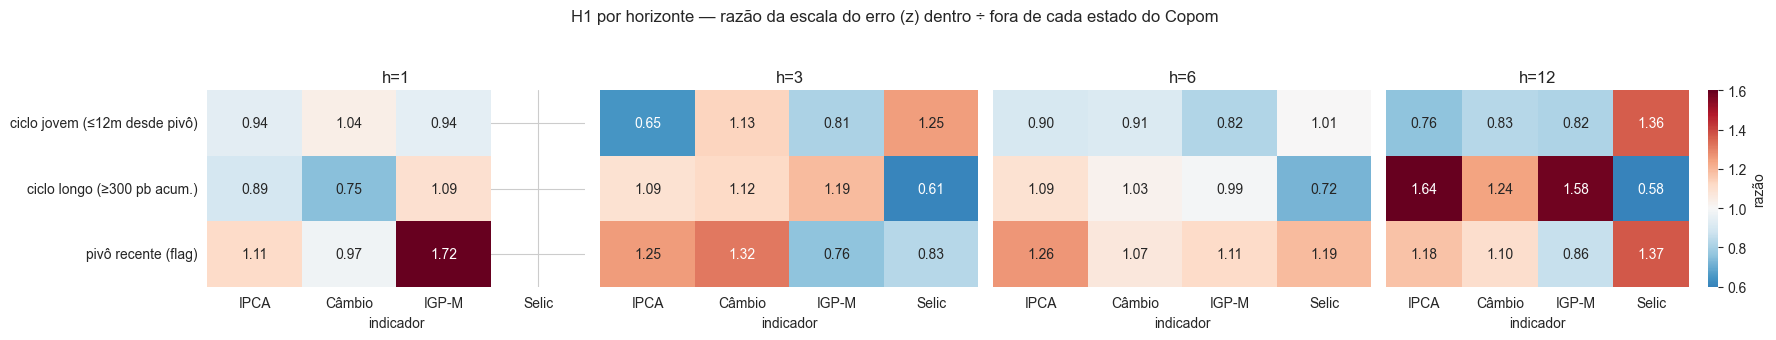

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.2), sharey=True)
for ax, h in zip(axes, HORIZONTES_MESES):
    sub = h1[h1["horizonte"] == h]
    piv = sub.pivot(index="estado", columns="indicador", values="razão")
    piv = piv.reindex(columns=[ROTULO[n] for n in ORDEM if ROTULO[n] in piv.columns])
    sns.heatmap(piv, annot=True, fmt=".2f", cmap="RdBu_r", center=1.0, vmin=0.6, vmax=1.6,
                ax=ax, cbar=(h == HORIZONTES_MESES[-1]), cbar_kws={"label": "razão"})
    ax.set_title(f"h={h}")
    ax.set_ylabel("" if h != HORIZONTES_MESES[0] else None)
plt.suptitle("H1 por horizonte — razão da escala do erro (z) dentro ÷ fora de cada estado do Copom", y=1.05)
plt.tight_layout()
plt.show()

**H1 continua rejeitada com a versão por horizonte** (e agora de forma mais granular: 48 combinações em vez de 12). Das 48, **4 vão na direção prevista** (mais incerto dentro do estado), **8 vão na direção oposta**, e **36 são não significativas**. A proporção de "acertos" da hipótese (4/48 ≈ 8%) é igual à da versão agregada (1/12 ≈ 8%) — estratificar por horizonte não inflou nem esvaziou o resultado, só o tornou mais confiável. O estado do ciclo do Copom (idade, magnitude acumulada, recência do pivô) **não é** um indicador útil de que o Focus vai errar mais.

## 3. H2 — a escala dos erros recentes ajuda?

Para cada previsão, `S_t` é a média de `|erro|` das 12 previsões mais recentes **do mesmo horizonte** cujo alvo já estava resolvido na data da decisão (defasagem de 60 dias, cobrindo a PNADC). Comparamos três formas de escala, todas com o fator multiplicativo ajustado só no treino de cada fold (mesma CV purgada da Etapa 5):

- **B0′** — `k · σ_Focus` (a base)
- **B4a** — `c · S_t` (só o erro recente)
- **B4b** — `c · √(σ_Focus · S_t)` (média geométrica: o sinal do Focus corrigido pelo erro recente)

Nada aqui foi ajustado olhando o resultado: uma única configuração (12 erros, defasagem de 60 dias).

In [4]:
def rodar_h2(nome):
    p = paineis[nome]
    y, h, sd = p["erro_focus"].to_numpy(), p["horizonte"].to_numpy(), p["desvio_padrao_focus"].to_numpy()
    d, td = p[COL_DATA[nome]], p["data_travamento"]
    n = len(y)

    S = np.full(n, np.nan)
    for hh in HORIZONTES_MESES:
        idx = np.flatnonzero(h == hh)
        S[idx] = escala_erros_resolvidos(d.iloc[idx], td.iloc[idx], y[idx], n_ultimos=12, defasagem_dias=60)

    Q = {k: np.full((n, len(TAUS)), np.nan) for k in ("B0k", "B4a", "B4b")}
    for tr, te in folds_seguros(d, 5, EMBARGO):
        for hh in HORIZONTES_MESES:
            mt, ms = tr[h[tr] == hh], te[h[te] == hh]
            if len(ms) == 0 or len(mt) < 20:
                continue
            try:
                Q["B0k"][ms] = quantis_normais(sd[ms], TAUS, ajustar_fator_sigma(y[mt], sd[mt], TAUS))
            except ValueError:
                continue
            ok = np.isfinite(S[mt]) & (S[mt] > 0)
            if ok.sum() < 20:
                continue
            ca = ajustar_fator_sigma(y[mt][ok], S[mt][ok], TAUS)
            cb = ajustar_fator_sigma(y[mt][ok], np.sqrt(sd[mt][ok] * S[mt][ok]), TAUS)
            v = ms[np.isfinite(S[ms]) & (S[ms] > 0)]
            Q["B4a"][v] = quantis_normais(S[v], TAUS, ca)
            Q["B4b"][v] = quantis_normais(np.sqrt(sd[v] * S[v]), TAUS, cb)
    return y, d, Q


NOME = {"B0k": "B0′ σ×k (base)", "B4a": "B4a erro recente", "B4b": "B4b híbrido"}
linhas = []
for n in ORDEM:
    y, d, Q = rodar_h2(n)
    m = np.all([np.isfinite(Q[k]).all(axis=1) for k in Q], axis=0)
    virada = np.array([eh_virada(x) for x in d[m]])
    base = crps_por_linha(y[m], Q["B0k"][m], TAUS).mean()
    for k in Q:
        q = Q[k][m]
        crps = crps_por_linha(y[m], q, TAUS).mean()
        cv = lambda mm: cobertura(y[m][mm], q[mm, J05], q[mm, J95])
        linhas.append({"indicador": ROTULO[n], "método": NOME[k], "n": int(m.sum()),
                       "skill vs B0′ (%)": 100 * (1 - crps / base),
                       "cob. 90% marginal": cobertura(y[m], q[:, J05], q[:, J95]),
                       "cob. 90% calmo": cv(~virada), "cob. 90% virada": cv(virada)})
h2 = pd.DataFrame(linhas)
display(h2.set_index(["indicador", "método"]).round(3))

n  skill vs B0′ (%)  cob. 90% marginal  \
indicador método                                                       
IPCA      B0′ σ×k (base)    701             0.000              0.800   
          B4a erro recente  701             0.549              0.825   
          B4b híbrido       701             1.469              0.842   
Câmbio    B0′ σ×k (base)    701             0.000              0.830   
          B4a erro recente  701            -4.142              0.765   
          B4b híbrido       701            -1.074              0.819   
IGP-M     B0′ σ×k (base)    701             0.000              0.813   
          B4a erro recente  701            -2.051              0.802   
          B4b híbrido       701            -0.099              0.826   
Selic     B0′ σ×k (base)    442             0.000              0.814   
          B4a erro recente  442            -5.388              0.742   
          B4b híbrido       442            -1.363              0.796   

                            cob. 90% calmo  cob. 90% virada  
indicador método                                             
IPCA      B0′ σ×k (base)             0.865            0.608  
          B4a erro recente           0.857            0.727  
          B4b híbrido                0.886            0.710  
Câmbio    B0′ σ×k (base)             0.840            0.801  
          B4a erro recente           0.764            0.767  
          B4b híbrido                0.823            0.807  
IGP-M     B0′ σ×k (base)             0.844            0.722  
          B4a erro recente           0.819            0.750  
          B4b híbrido                0.846            0.767  
Selic     B0′ σ×k (base)             0.851            0.717  
          B4a erro recente           0.764            0.683  
          B4b híbrido                0.832            0.700

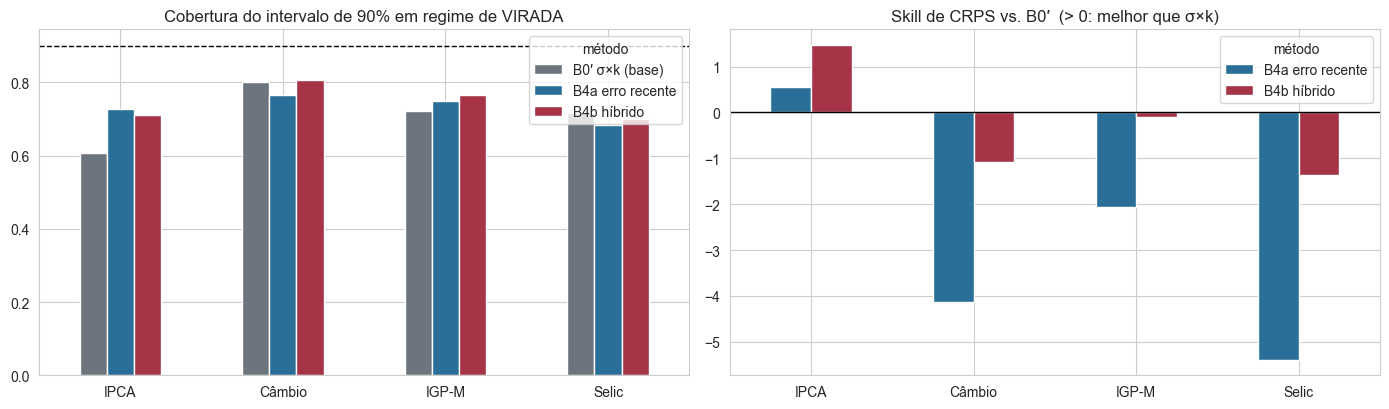

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
piv = h2.pivot(index="indicador", columns="método", values="cob. 90% virada").loc[[ROTULO[n] for n in ORDEM]]
piv[[NOME[k] for k in NOME]].plot(kind="bar", ax=axes[0], color=["#6c757d", "#2a6f97", "#a63446"])
axes[0].axhline(0.90, color="black", linestyle="--", linewidth=1)
axes[0].set_title("Cobertura do intervalo de 90% em regime de VIRADA")
axes[0].set_xlabel(""); axes[0].tick_params(axis="x", rotation=0)

piv2 = h2.pivot(index="indicador", columns="método", values="skill vs B0′ (%)").loc[[ROTULO[n] for n in ORDEM]]
piv2[[NOME["B4a"], NOME["B4b"]]].plot(kind="bar", ax=axes[1], color=["#2a6f97", "#a63446"])
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set_title("Skill de CRPS vs. B0′  (> 0: melhor que σ×k)")
axes[1].set_xlabel(""); axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

**H2 ajuda marginalmente em um indicador e é neutra ou pior nos demais.**

- **IPCA:** a escala do erro recente eleva a cobertura em virada de 61% para 71–73% e melhora o CRPS em 0,5–1,5%. É o único ganho, e é pequeno.
- **Câmbio, IGP-M e Selic:** o CRPS **piora** (−0,1% a −5,4%) e a cobertura em regime calmo cai (Selic: 85% → 76% com o erro recente puro). O híbrido (B4b) limita o estrago, sem ganho.

**Nenhuma variante fecha a lacuna:** a cobertura em virada fica em 68–81% contra 90% nominal. E o benefício no IPCA tem um custo: em regime calmo o intervalo passa a ser reajustado por ruído recente. A razão é a mesma que faz o ACI falhar na Selic (Etapa 5): a escala do erro recente informa pouco sobre a escala do erro *futuro* quando o regime muda — que é precisamente o caso que se quer capturar.

## 4. H3 — a direção do ciclo (aperto vs. afrouxamento) muda o erro?

Diferente de H1, que testa *idade*, *magnitude* e *recência* do ciclo, H3 testa a **direção** em si: o erro do Focus se comporta de forma diferente quando a Selic está subindo (`aperto`) do que quando está caindo (`afrouxamento`)? `manutenção` fica de fora da comparação (poucas observações, é o estado de transição).

Dois testes, ambos por horizonte:

- **Viés** (`erro_focus`, com sinal) — via `OLS(erro ~ 1 + D_aperto)` com erro-padrão **HAC/Newey-West** (`maxlags = h`), o mesmo padrão da Etapa 3. Aqui importa a direção: se `aperto` tem viés diferente de `afrouxamento`.
- **Magnitude** (`z = |erro|/σ`) — Mann-Whitney, como em H1.

O teste de viés é o mais exigente dos dois porque a autocorrelação é especialmente severa aqui: `aperto` e `afrouxamento` são sequências de meses **contíguos** (o mesmo ciclo dura vários meses seguidos), então um teste sem correção de autocorrelação (como um Mann-Whitney simples no viés) tende a inflar a significância.

In [6]:
linhas = []
for n in ORDEM:
    p = paineis[n]
    p = p[(p["desvio_padrao_focus"] > 0) & (p["regime_fase_ciclo"].isin(["aperto", "afrouxamento"]))].copy()
    p["D_aperto"] = (p["regime_fase_ciclo"] == "aperto").astype(float)
    col = COL_DATA[n]
    for h in HORIZONTES_MESES:
        s = p[p["horizonte"] == h].sort_values(col)
        n_ap, n_af = int(s["D_aperto"].sum()), int((1 - s["D_aperto"]).sum())
        if n_ap < 5 or n_af < 5:
            continue
        X = sm.add_constant(s["D_aperto"].to_numpy())
        m = sm.OLS(s["erro_focus"].to_numpy(), X).fit(cov_type="HAC", cov_kwds={"maxlags": h})
        z_ap, z_af = s.loc[s["D_aperto"] == 1, "z"], s.loc[s["D_aperto"] == 0, "z"]
        p_mwu = stats.mannwhitneyu(z_ap, z_af, alternative="two-sided").pvalue
        linhas.append({
            "indicador": ROTULO[n], "horizonte": h, "n aperto": n_ap, "n afrox.": n_af,
            "ME aperto": s.loc[s["D_aperto"] == 1, "erro_focus"].mean(),
            "ME afrouxamento": s.loc[s["D_aperto"] == 0, "erro_focus"].mean(),
            "delta (HAC)": m.params[1], "p viés (HAC)": m.pvalues[1],
            "z aperto": z_ap.median(), "z afrouxamento": z_af.median(), "p magnitude (M-W)": p_mwu,
        })
h3 = pd.DataFrame(linhas).set_index(["indicador", "horizonte"])
display(h3.round(4))

n aperto  n afrox.  ME aperto  ME afrouxamento  \
indicador horizonte                                                   
IPCA      1               114       131     0.0642           0.0270   
          3               114       129     0.0796           0.0349   
          6               114       126     0.0797           0.0565   
          12              108       126     0.0430           0.1169   
Câmbio    1               114       131     0.0001           0.0355   
          3               114       129    -0.0052           0.0808   
          6               114       126    -0.0267           0.1531   
          12              108       126    -0.0591           0.2975   
IGP-M     1               114       131    -0.0463           0.1926   
          3               114       129    -0.0797           0.3041   
          6               114       126    -0.1400           0.3780   
          12              108       126    -0.1780           0.4269   
Selic     1                71        82    -0.0059          -0.0091   
          3                72        86     0.0742          -0.1076   
          6                77        83     0.2483          -0.1230   
          12               74        82     0.3967           0.1916   

                     delta (HAC)  p viés (HAC)  z aperto  z afrouxamento  \
indicador horizonte                                                        
IPCA      1               0.0372        0.2875    1.3150          1.6000   
          3               0.0448        0.4263    1.9499          1.8571   
          6               0.0232        0.7029    1.9542          2.1623   
          12             -0.0739        0.2542    2.1270          2.5714   
Câmbio    1              -0.0354        0.0617    0.8850          0.7475   
          3              -0.0860        0.1127    1.8010          1.1538   
          6              -0.1798        0.0894    2.2713          1.6590   
          12             -0.3566        0.0568    2.0343          3.1466   
IGP-M     1              -0.2389        0.0385    1.9484          2.1304   
          3              -0.3839        0.0253    2.5917          3.1842   
          6              -0.5180        0.0067    2.7991          3.7841   
          12             -0.6048        0.0032    2.9342          4.0333   
Selic     1               0.0032        0.9079    0.0000          0.0000   
          3               0.1817        0.0601    1.1098          1.0016   
          6               0.3713        0.2322    1.6358          2.0270   
          12              0.2051        0.7967    2.0845          3.4354   

                     p magnitude (M-W)  
indicador horizonte                     
IPCA      1                     0.4775  
          3                     0.3062  
          6                     0.7829  
          12                    0.1288  
Câmbio    1                     0.1944  
          3                     0.0118  
          6                     0.0622  
          12                    0.0008  
IGP-M     1                     0.2097  
          3                     0.0574  
          6                     0.0052  
          12                    0.0037  
Selic     1                     0.7066  
          3                     0.7419  
          6                     0.1769  
          12                    0.0117

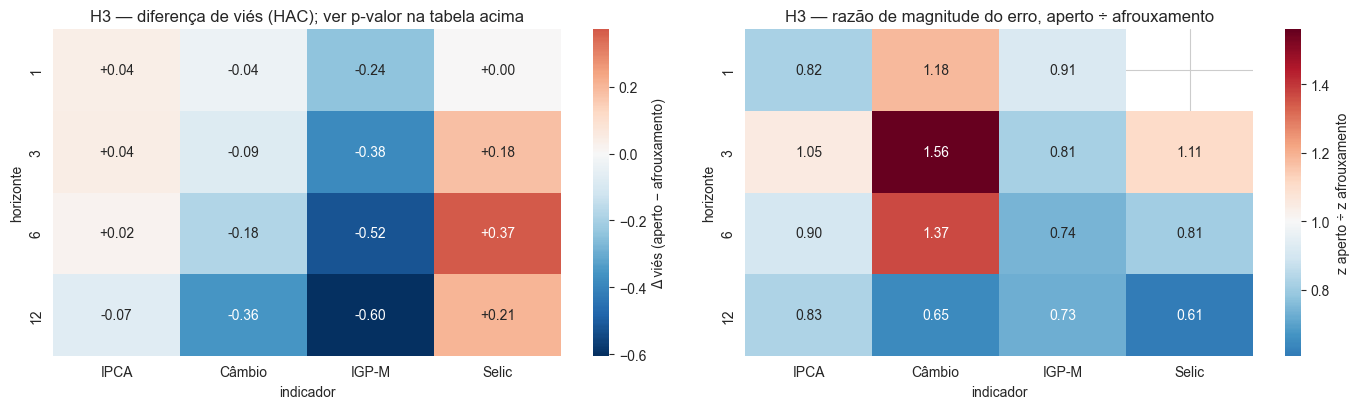

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
piv_vies = h3["delta (HAC)"].unstack("indicador")[[ROTULO[n] for n in ORDEM]]
sig_vies = (h3["p viés (HAC)"] < 0.05).unstack("indicador")[[ROTULO[n] for n in ORDEM]]
sns.heatmap(piv_vies, annot=True, fmt="+.2f", cmap="RdBu_r", center=0, ax=axes[0],
            cbar_kws={"label": "Δ viés (aperto − afrouxamento)"})
axes[0].set_title("H3 — diferença de viés (HAC); ver p-valor na tabela acima")

piv_z = (h3["z aperto"] / h3["z afrouxamento"]).unstack("indicador")[[ROTULO[n] for n in ORDEM]]
sns.heatmap(piv_z, annot=True, fmt=".2f", cmap="RdBu_r", center=1.0, ax=axes[1],
            cbar_kws={"label": "z aperto ÷ z afrouxamento"})
axes[1].set_title("H3 — razão de magnitude do erro, aperto ÷ afrouxamento")
plt.tight_layout()
plt.show()

In [8]:
# Robustez: H3 (IGP-M) sobrevive fora dos regimes de virada, ou e so a virada reaparecendo?
def eh_virada(d):
    d = pd.Timestamp(d)
    return (pd.Timestamp("2020-01-01") <= d <= pd.Timestamp("2022-12-31")) or d >= pd.Timestamp("2026-01-01")

p_igpm = paineis["igpm"]
p_sv = p_igpm[(~p_igpm["referencia_periodo"].apply(eh_virada)) & p_igpm["regime_fase_ciclo"].isin(["aperto", "afrouxamento"])].copy()
p_sv["D_aperto"] = (p_sv["regime_fase_ciclo"] == "aperto").astype(float)

linhas = []
for h in HORIZONTES_MESES:
    s = p_sv[p_sv["horizonte"] == h].sort_values("referencia_periodo")
    n_ap, n_af = int(s["D_aperto"].sum()), int((1 - s["D_aperto"]).sum())
    if n_ap < 5 or n_af < 5:
        continue
    X = sm.add_constant(s["D_aperto"].to_numpy())
    m = sm.OLS(s["erro_focus"].to_numpy(), X).fit(cov_type="HAC", cov_kwds={"maxlags": h})
    linhas.append({"horizonte": h, "n aperto": n_ap, "n afrox.": n_af,
                   "delta (HAC)": m.params[1], "p viés (HAC)": m.pvalues[1]})
display(pd.DataFrame(linhas).set_index("horizonte").round(4))

,n aperto,n afrox.,delta (HAC),p viés (HAC)
horizonte,,,,
1,90,111,-0.1064,0.3049
3,90,109,-0.2349,0.0881
6,90,106,-0.3258,0.0283
12,90,100,-0.3945,0.0110


**Resultado, com a correção HAC aplicada ao viés:**

| Indicador | Viés (HAC) | Magnitude (M-W) |
|---|---|---|
| IPCA | nenhum horizonte significativo | nenhum horizonte significativo |
| Câmbio | nenhum horizonte cruza 5% (0,057–0,113), mas o sinal é o mesmo nos 4 e a magnitude do delta cresce com o horizonte (−0,04 → −0,36) | h=3 e h=12 significativos |
| **IGP-M** | **significativo nos 4 horizontes** (p=0,039 / 0,025 / 0,007 / 0,003), fortalecendo com o horizonte | h=6 e h=12 significativos |
| Selic | nenhum horizonte significativo (mais próximo: h=3, p=0,060) | só h=12 significativo |

**Só o IGP-M sobrevive com rigor.** O Focus subestima o IGP-M em ciclos de afrouxamento e é aproximadamente neutro (ou levemente conservador) em ciclos de aperto, em todos os horizontes, com significância crescente.

**Isso corrige uma leitura apressada.** Um teste sem correção de autocorrelação (Mann-Whitney direto no viés, sem HAC) mostrava Câmbio e Selic como "fortemente significativos" (p < 0,0001). A correção os derruba para não significativos. A razão é a autocorrelação severa dentro de cada estado: `aperto` e `afrouxamento` são sequências de meses **contíguos** — o mesmo ciclo dura vários meses seguidos —, então cada estado tem muito menos informação independente do que seu número de linhas sugere. É o mesmo cuidado da Etapa 3, aplicado aqui a uma comparação de dois grupos em vez de uma média única.

**O achado do IGP-M não é apenas "virada" reaparecendo.** Como `afrouxamento` inclui o corte da COVID (2020) e `aperto` inclui o aperto pós-COVID (2021-22) — os próprios regimes de virada definidos na Etapa 5 —, cabia perguntar se H3 só estava redescobrindo esse efeito por outra porta. Excluindo inteiramente as linhas de virada (2020-22 e 2026), o efeito **sobrevive em h=6 (p=0,028) e h=12 (p=0,011)**, enfraquece em h=3 (p=0,088) e desaparece em h=1 (que já era o mais fraco, mesmo com virada incluída). É um efeito mais amplo que a pandemia, presente em ciclos normais de afrouxamento — só que menos forte fora deles.

**Uma distinção importante em relação ao resto do notebook:** H1 e H2 procuram um sinal para a *largura* do intervalo (a incerteza). H3 encontra algo diferente — um sinal para a *direção* do viés no IGP-M. Isso não resolve o problema central de cobertura em regime de virada (que é sobre dispersão, não sobre o centro da distribuição), mas é um candidato genuíno a uma correção de **ponto** para o IGP-M — na linha do que a Etapa 4 tentou e não sustentou para o conjunto geral de features. Diferente daquele caso, esta associação sobrevive a um teste de robustez (excluir os anos de virada), mas ainda não foi validada fora da amostra com a mesma disciplina da Etapa 4 (CV purgada, Diebold-Mariano). Fica como candidato para uma extensão futura, não como correção pronta para uso.

## 5. Quanto seria preciso alargar? (medida *ex-post*, apenas informativa)

Se nenhum sinal ex-ante reconhece a virada a tempo, resta a pergunta prática: **quanto** o intervalo do B0′ precisaria ser mais largo em regime de virada para cobrir 90%? Aqui `k_virada / k_calmo` é estimado *dentro* de cada regime, com os próprios dados do regime — logo é uma **medida diagnóstica, não uma regra utilizável** (ninguém saberia de antemão que está em virada).

In [9]:
linhas = []
for n in ORDEM:
    p = paineis[n].dropna(subset=["z"])
    p = p[p["desvio_padrao_focus"] > 0]
    for h in HORIZONTES_MESES:
        s = p[p["horizonte"] == h]
        if s["virada"].sum() < 8 or (~s["virada"]).sum() < 20:
            continue
        k_c = ajustar_fator_sigma(s.loc[~s["virada"], "erro_focus"].to_numpy(), s.loc[~s["virada"], "desvio_padrao_focus"].to_numpy(), TAUS)
        k_v = ajustar_fator_sigma(s.loc[s["virada"], "erro_focus"].to_numpy(), s.loc[s["virada"], "desvio_padrao_focus"].to_numpy(), TAUS)
        linhas.append({"indicador": ROTULO[n], "horizonte": h, "n virada": int(s["virada"].sum()), "k calmo": k_c, "k virada": k_v, "k_virada / k_calmo": k_v / k_c})
alarg = pd.DataFrame(linhas)
display(alarg.set_index(["indicador", "horizonte"]).round(2))
resumo_alarg = alarg.groupby("indicador")["k_virada / k_calmo"].agg(["min", "median", "max"]).round(2)
display(resumo_alarg)

n virada  k calmo  k virada  k_virada / k_calmo
indicador horizonte                                                 
IPCA      1                44     1.97      2.52                1.28
          3                44     2.52      4.94                1.96
          6                44     2.81      5.49                1.95
          12               44     2.97      5.98                2.02
Câmbio    1                44     1.26      1.57                1.24
          3                44     2.04      1.94                0.95
          6                44     2.89      2.19                0.76
          12               44     3.31      3.28                0.99
IGP-M     1                44     3.12      3.13                1.00
          3                44     4.33      5.51                1.27
          6                44     4.61      7.38                1.60
          12               44     4.76      9.13                1.92
Selic     1                29     0.02      0.02                1.00
          3                30     1.63      1.83                1.12
          6                30     2.48      4.02                1.62
          12               30     3.27      6.15                1.88

,min,median,max
indicador,,,
Câmbio,0.76,0.97,1.24
IGP-M,1.00,1.44,1.92
IPCA,1.28,1.96,2.02
Selic,1.00,1.37,1.88


## 6. Conclusões

**Nenhum sinal ex-ante testado reconhece o regime de virada a tempo.** O estado do ciclo do Copom (H1) não separa a escala do erro de forma consistente — quando separa, é majoritariamente na direção oposta. A escala dos erros recentes (H2) ajuda marginalmente o IPCA e prejudica os demais. O achado da Etapa 5 permanece: **em regime de virada, um intervalo de "90%" cobre na prática ~60–80%**, e não há, com a informação disponível na data da previsão, um gatilho que permita corrigi-lo.

**A medida ex-post mostra a magnitude do problema.** Estimado *dentro* dos regimes de virada (portanto sem valor operacional), o intervalo precisaria ser mais largo por um fator mediano de **≈ 2,0× no IPCA**, **1,4× no IGP-M** e **1,4× na Selic**, crescendo com o horizonte (IPCA e IGP-M: de ~1,0–1,3× em `h=1` a ~1,9–2,0× em `h=12`; Selic: 1,0× → 1,9×). O **Câmbio é a exceção**: ~1,0×, isto é, sua incerteza não muda com o regime — coerente com um passeio aleatório.

**O que isso significa para o usuário do boletim.**

1. Reescalar o σ do Focus por indicador × horizonte (B0′) é a melhor alternativa disponível e recupera a maior parte do valor em condições normais (Etapa 5).
2. Esse intervalo é **otimista em regimes de virada**, e não há como saber de antemão que se está em um. A recomendação prática honesta é **tratar o intervalo como um piso de incerteza, e não como uma cobertura garantida**, sobretudo em horizontes longos de IPCA, IGP-M e Selic.
3. Se uma margem de segurança fosse adotada por prudência, a ordem de grandeza sugerida pelos dados é de 1,5–2× nos horizontes longos desses três indicadores — mas isso é uma **calibração ex-post sobre 29–44 observações por horizonte**, não uma regra validada fora da amostra.

**Ressalvas.** (i) "Virada" foi definida por data (2020–2022 e 2026); 2026 tem poucas observações. (ii) Os estados de H1 usam cortes fixados a priori (12 meses, 300 pb), mas outros cortes poderiam dar resultados diferentes — não os exploramos, para não introduzir seleção pós-hoc. (iii) H2 testou uma única configuração (12 erros, defasagem de 60 dias). (iv) A Desocupação ficou fora por amostra efetiva insuficiente (Etapas 4 e 5). (v) O fato de duas hipóteses naturais terem falhado não prova que nenhum sinal existe — só que não encontramos um com estes dados.